# Part 11 — Exploratory Data Analysis (EDA)

**Project:** Clean Sales Dataset  
**Input:** `data/clean_sales.csv` from Phase 3.2

## Goal
Explore the cleaned sales data, answer business questions with evidence, identify limitations, and recommend reasonable next steps.

> **Important:** This dataset is suitable for practicing EDA. Unless it contains verified revenue, cost, profit, customer, and date fields, do not use it to make claims about profitability, customer lifetime value, or sales trends over time.


## 1. Business questions

We will investigate these questions:

1. Which product categories have the highest order-row counts and total quantity?
2. Which cities have the highest total quantity?
3. How are quantities and product weights distributed, and are there potential outliers?
4. Is there a relationship between order quantity and weight?
5. How many records still need data-quality review, and which fields need attention?

**How to interpret results:** These questions describe the dataset. They do not automatically explain *why* a category or city performs differently.


**Required input:** copy the real cleaned Phase 3.2 file to `data/clean_sales.csv` beside this notebook. This notebook deliberately does **not** create or substitute a fallback/sample dataset. If the real file is missing, execution stops with a clear error so the analysis cannot accidentally report sample values as business findings. All generated artifacts use the `task_clean_sales` filename prefix and are saved under `data/`.


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / "data"
DATA_PATH = DATA_DIR / "clean_sales.csv"
CHART_DIR = DATA_DIR / "task_clean_sales_eda_charts"
DATA_DIR.mkdir(parents=True, exist_ok=True)
CHART_DIR.mkdir(parents=True, exist_ok=True)

if not DATA_PATH.is_file():
    raise FileNotFoundError(
        f"Real cleaned dataset not found: {DATA_PATH}\n"
        "Copy the intended Phase 3.2 data/clean_sales.csv here. No fallback sample is created."
    )

df = pd.read_csv(DATA_PATH)
if df.empty:
    raise ValueError(f"The intended dataset is empty: {DATA_PATH}")
print(f"SOURCE VERIFIED: {DATA_PATH.resolve()}")
print(f"Rows: {len(df):,} | Columns: {df.shape[1]:,}")
display(df.head())


SOURCE VERIFIED: E:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\clean_sales.csv
Rows: 20 | Columns: 7


,Order_ID,City,Category,Order_Status,Quantity,Weight_kg,Needs_Review
0,1001,Lahore,Electronics,Completed,2,1.2,False
1,1002,Karachi,Clothing,Shipped,3,0.4,False
2,1003,Lahore,Grocery,Completed,10,5.0,False
3,1004,Islamabad,Furniture,Pending,1,8.5,False
4,1005,Karachi,Electronics,Cancelled,2,2.0,False


## 3. Initial exploration and data quality

Check the dataset's size, column types, summary statistics, missing values, duplicates, and available categories. These checks help us decide which analyses are safe to perform.


In [2]:
print("Dataset shape:", df.shape)

print("\nColumn data types:")
display(df.dtypes.rename("dtype").to_frame())

print("\nSummary statistics (numeric columns):")
display(df.describe(include="number").T)

print("\nSummary statistics (all columns):")
display(df.describe(include="all").T)

quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique(dropna=True),
})
display(quality.sort_values("missing_count", ascending=False))

print("Exact duplicate rows:", int(df.duplicated().sum()))


Dataset shape: (20, 7)

Column data types:


,dtype
Order_ID,int64
City,str
Category,str
Order_Status,str
Quantity,int64
Weight_kg,float64
Needs_Review,bool



Summary statistics (numeric columns):


,count,mean,std,min,25%,50%,75%,max
Order_ID,20.0,1010.50,5.916080,1001.0,1005.75,1010.5,1015.250,1020.0
Quantity,20.0,4.00,3.387283,1.0,1.75,2.5,5.500,12.0
Weight_kg,20.0,3.28,2.712078,0.4,1.10,2.3,4.625,9.0



Summary statistics (all columns):


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Order_ID,20.0,NaN,NaN,NaN,1010.5,5.91608,1001.0,1005.75,1010.5,1015.25,1020.0
City,20,6,Lahore,6,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Category,20,5,Electronics,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Order_Status,20,5,Completed,10,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,20.0,NaN,NaN,NaN,4.0,3.387283,1.0,1.75,2.5,5.5,12.0
Weight_kg,20.0,NaN,NaN,NaN,3.28,2.712078,0.4,1.1,2.3,4.625,9.0
Needs_Review,20,2,False,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,missing_count,missing_percent,unique_values
Order_ID,0,0.0,20
City,0,0.0,6
Category,0,0.0,5
Order_Status,0,0.0,5
Quantity,0,0.0,10
Weight_kg,0,0.0,20
Needs_Review,0,0.0,2


Exact duplicate rows: 0


In [3]:
# Review distinct values for common categorical columns, when present.
for column in ["City", "Category", "Order_Status"]:
    if column in df.columns:
        print(f"\nDistinct values in {column}:")
        print(sorted(df[column].dropna().astype(str).unique().tolist()))



Distinct values in City:
['Faisalabad', 'Islamabad', 'Karachi', 'Lahore', 'Multan', 'Peshawar']

Distinct values in Category:
['Clothing', 'Electronics', 'Furniture', 'Grocery', 'Home & Kitchen']

Distinct values in Order_Status:
['Cancelled', 'Completed', 'Pending', 'Returned', 'Shipped']


### Data-quality interpretation

After running the cells above, write down:
- Which columns have missing values?
- Are there duplicate rows, and should they really be duplicates?
- Do category, city, and status values look consistent?
- Are numeric-looking columns stored as numbers or text?

Do not delete missing values or duplicates automatically. First determine what they mean in the business context.


## 4. Prepare numeric columns

Convert `Quantity` and `Weight_kg` to numeric values only if those columns exist. Invalid text will become missing (`NaN`), so we record how many values could not be converted.


In [4]:
numeric_columns = [c for c in ["Quantity", "Weight_kg"] if c in df.columns]
conversion_report = []

for column in numeric_columns:
    before = df[column].notna().sum()
    converted = pd.to_numeric(df[column], errors="coerce")
    newly_missing = int((df[column].notna() & converted.isna()).sum())
    df[column] = converted
    conversion_report.append({
        "column": column,
        "non_missing_before": int(before),
        "newly_missing_after_conversion": newly_missing,
    })

display(pd.DataFrame(conversion_report))
display(df[numeric_columns].describe().T if numeric_columns else pd.DataFrame(
    {"Note": ["No Quantity or Weight_kg column found. Update the column names if your dataset uses different names."]}
))


,column,non_missing_before,newly_missing_after_conversion
0,Quantity,20,0
1,Weight_kg,20,0


,count,mean,std,min,25%,50%,75%,max
Quantity,20.0,4.00,3.387283,1.0,1.75,2.5,5.500,12.0
Weight_kg,20.0,3.28,2.712078,0.4,1.10,2.3,4.625,9.0


## 5. Distribution analysis

Histograms help show the shape and spread of numeric values. Box plots can highlight unusually high or low values, but a flagged point is not automatically an error.


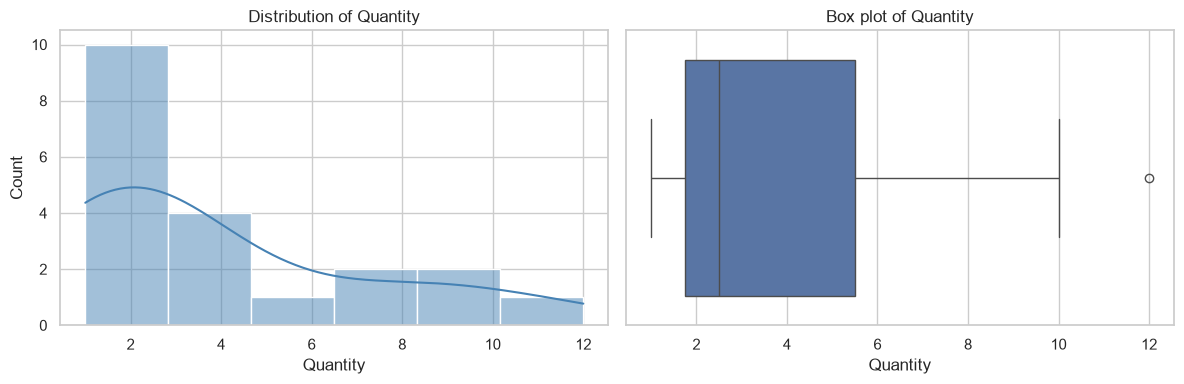

Numerical summary for Quantity:


,count,mean,std,min,25%,50%,75%,max
value,20.0,4.0,3.387283,1.0,1.75,2.5,5.5,12.0


Median: 2.50; IQR: 3.75


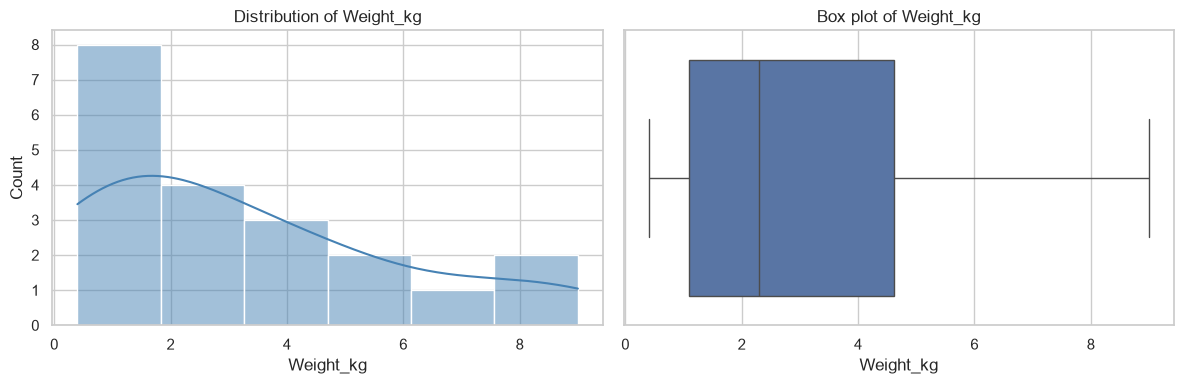

Numerical summary for Weight_kg:


,count,mean,std,min,25%,50%,75%,max
value,20.0,3.28,2.712078,0.4,1.1,2.3,4.625,9.0


Median: 2.30; IQR: 3.52


In [5]:
for column in numeric_columns:
    values = df[column].dropna()
    if values.empty:
        print(f"Skipping {column}: no numeric values.")
        continue

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sns.histplot(values, kde=True, ax=axes[0], color="steelblue")
    axes[0].set_title(f"Distribution of {column}")
    axes[0].set_xlabel(column)

    sns.boxplot(x=values, ax=axes[1])
    axes[1].set_title(f"Box plot of {column}")
    axes[1].set_xlabel(column)

    plt.tight_layout()
    fig.savefig(CHART_DIR / f"task_clean_sales_{column.lower()}_distribution.png", dpi=150, bbox_inches="tight")
    plt.show()

    print(f"Numerical summary for {column}:")
    display(values.describe().to_frame("value").T)
    print(f"Median: {values.median():.2f}; IQR: {(values.quantile(0.75) - values.quantile(0.25)):.2f}")


### Distribution insights (computed from the loaded cleaned dataset)

The final insight/report cell below calculates mean, median, IQR, skewness, and Tukey-fence potential outliers directly from the verified input. Interpret potential outliers as review candidates, not automatic errors.


## 6. Segment analysis

Compare category, city, and order-status groups. `Order_Rows` counts rows with a non-missing `Order_ID`; it is not necessarily a count of unique orders. If one order can have multiple product rows, use `nunique` for unique order counts.


,Order_Rows,Unique_Orders,Total_Quantity,Average_Quantity,Average_Weight_kg
Category,,,,,
Clothing,5,5,19,3.8,0.600000
Electronics,5,5,8,1.6,1.720000
Furniture,3,3,3,1.0,8.333333
Grocery,5,5,46,9.2,4.660000
Home & Kitchen,2,2,4,2.0,2.850000


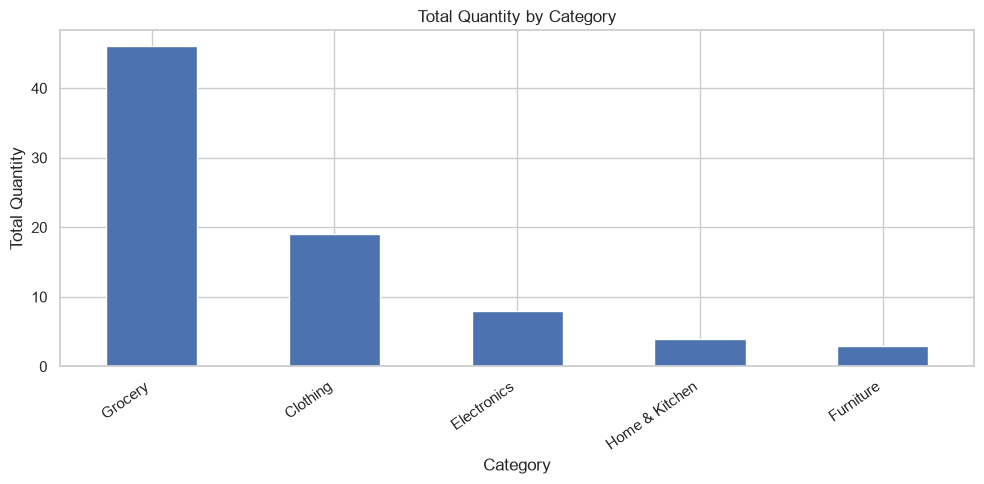

In [6]:
# Category comparison
if "Category" in df.columns:
    aggregations = {}
    if "Order_ID" in df.columns:
        aggregations["Order_Rows"] = ("Order_ID", "count")
        aggregations["Unique_Orders"] = ("Order_ID", "nunique")
    if "Quantity" in df.columns:
        aggregations["Total_Quantity"] = ("Quantity", "sum")
        aggregations["Average_Quantity"] = ("Quantity", "mean")
    if "Weight_kg" in df.columns:
        aggregations["Average_Weight_kg"] = ("Weight_kg", "mean")

    if aggregations:
        category_summary = df.groupby("Category", dropna=False).agg(**aggregations).sort_index()
        display(category_summary)
        category_summary.to_csv(DATA_DIR / "task_clean_sales_category_analysis.csv")

        metric = "Total_Quantity" if "Total_Quantity" in category_summary.columns else category_summary.columns[0]
        category_summary[metric].sort_values(ascending=False).plot(kind="bar", figsize=(10, 5))
        plt.title(f"{metric.replace('_', ' ')} by Category")
        plt.ylabel(metric.replace("_", " "))
        plt.xlabel("Category")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "task_clean_sales_category_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("No suitable columns available for category aggregation.")
else:
    print("No Category column found.")


,Order_Rows,Unique_Orders,Total_Quantity,Average_Quantity
City,,,,
Faisalabad,2,2,13,6.500000
Islamabad,3,3,4,1.333333
Karachi,5,5,9,1.800000
Lahore,6,6,35,5.833333
Multan,2,2,10,5.000000
Peshawar,2,2,9,4.500000


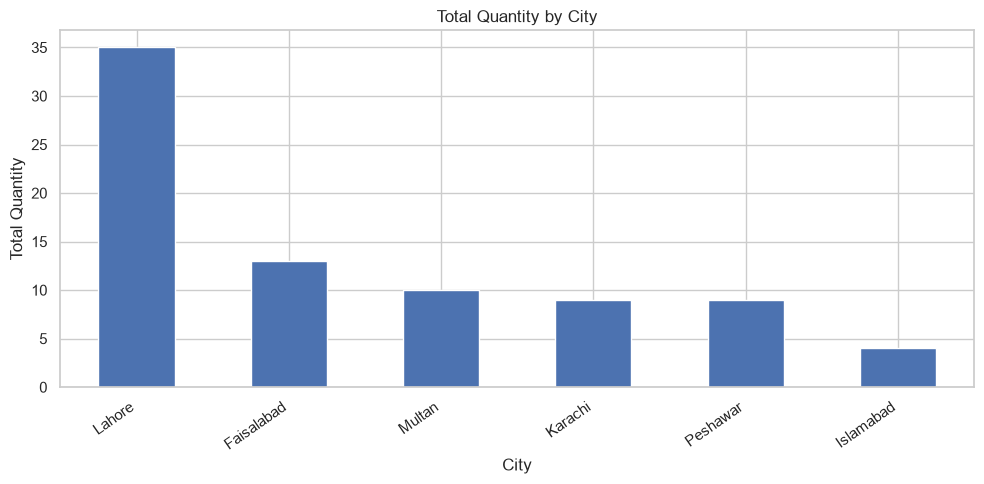

In [7]:
# City comparison
if "City" in df.columns:
    aggregations = {}
    if "Order_ID" in df.columns:
        aggregations["Order_Rows"] = ("Order_ID", "count")
        aggregations["Unique_Orders"] = ("Order_ID", "nunique")
    if "Quantity" in df.columns:
        aggregations["Total_Quantity"] = ("Quantity", "sum")
        aggregations["Average_Quantity"] = ("Quantity", "mean")

    if aggregations:
        city_summary = df.groupby("City", dropna=False).agg(**aggregations).sort_index()
        display(city_summary)
        city_summary.to_csv(DATA_DIR / "task_clean_sales_city_analysis.csv")

        metric = "Total_Quantity" if "Total_Quantity" in city_summary.columns else city_summary.columns[0]
        city_summary[metric].sort_values(ascending=False).plot(kind="bar", figsize=(10, 5))
        plt.title(f"{metric.replace('_', ' ')} by City")
        plt.ylabel(metric.replace("_", " "))
        plt.xlabel("City")
        plt.xticks(rotation=35, ha="right")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "task_clean_sales_city_comparison.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("No suitable columns available for city aggregation.")
else:
    print("No City column found.")


,row_count
Order_Status,
Completed,10
Shipped,4
Pending,3
Cancelled,2
Returned,1


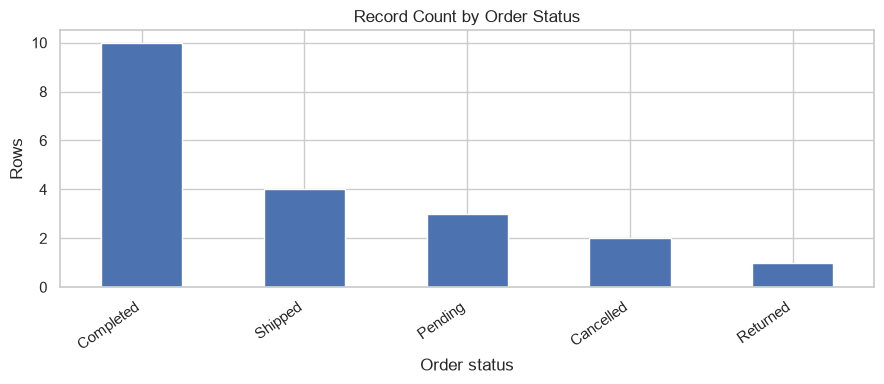

In [8]:
# Order status distribution
if "Order_Status" in df.columns:
    status_counts = df["Order_Status"].fillna("Missing").value_counts(dropna=False)
    display(status_counts.rename("row_count").to_frame())
    status_counts.to_csv(DATA_DIR / "task_clean_sales_status_analysis.csv", header=["row_count"])

    status_counts.plot(kind="bar", figsize=(9, 4))
    plt.title("Record Count by Order Status")
    plt.ylabel("Rows")
    plt.xlabel("Order status")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.savefig(CHART_DIR / "task_clean_sales_order_status_counts.png", dpi=150, bbox_inches="tight")
    plt.show()
else:
    print("No Order_Status column found.")


### Segment insights (computed from the loaded cleaned dataset)

The final insight/report cell identifies leaders separately by total quantity, non-null order-ID row count, unique order count, and mean quantity where those fields exist. These metrics answer different questions and should not be treated as interchangeable.


## 7. Relationship analysis

Check the relationship between quantity and weight if both columns exist. Correlation describes the strength and direction of a linear relationship; it does not prove that one variable causes the other.


Pearson correlation between Quantity and Weight_kg: 0.114


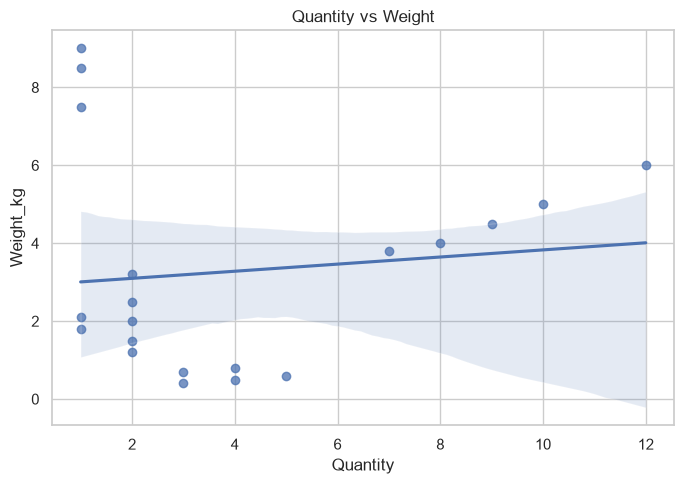

In [9]:
if {"Quantity", "Weight_kg"}.issubset(df.columns):
    pair = df[["Quantity", "Weight_kg"]].dropna()

    if len(pair) >= 2 and pair.nunique().min() > 1:
        correlation = pair["Quantity"].corr(pair["Weight_kg"], method="pearson")
        print(f"Pearson correlation between Quantity and Weight_kg: {correlation:.3f}")

        plt.figure(figsize=(7, 5))
        sns.regplot(data=pair, x="Quantity", y="Weight_kg", scatter_kws={"alpha": 0.75})
        plt.title("Quantity vs Weight")
        plt.tight_layout()
        plt.savefig(CHART_DIR / "task_clean_sales_quantity_vs_weight.png", dpi=150, bbox_inches="tight")
        plt.show()
    else:
        print("Not enough valid variation to calculate a meaningful correlation.")
else:
    print("Quantity and/or Weight_kg column missing; relationship analysis skipped.")


### Relationship interpretation (computed from the loaded cleaned dataset)

The final insight/report cell reports Pearson's r, sample size, scatter-plot interpretation, and the limitations of a small observational sample. Correlation does not establish causation.


## 8. Evidence-based findings, data-quality investigation, and recommendations

The next cell generates findings from the actual input file. It does not hard-code example numbers. It also exports flagged review records, the written report, and a run summary to `data/`.


In [10]:
# Build evidence-based findings and recommendations from the verified dataset.
findings = []
recommendations = []
report_lines = [
    "# EDA Insight & Business Analysis — Clean Sales Dataset", "",
    f"**Source file:** `{DATA_PATH.resolve()}`  ",
    f"**Rows:** {len(df):,} | **Columns:** {df.shape[1]:,}  ",
    "**Source policy:** This report was generated only after `data/clean_sales.csv` was found; no fallback sample was used.", ""
]

def add_finding(title, finding, evidence, interpretation, limitation):
    findings.append({"area": title, "finding": finding, "numerical_evidence": evidence,
                     "interpretation": interpretation, "limitation": limitation})
    report_lines.extend([f"### {len(findings)}. {title}", f"- **Finding:** {finding}",
                         f"- **Evidence:** {evidence}", f"- **Interpretation:** {interpretation}",
                         f"- **Limitation:** {limitation}", ""])

def fmt(v, digits=2):
    return f"{v:,.{digits}f}" if pd.notna(v) else "not available"

# Part A: distributions
for col, unit in [("Quantity", "units"), ("Weight_kg", "kg")]:
    if col not in df.columns:
        add_finding(f"{col} distribution", f"{col} is unavailable in the dataset.",
                    "Column absent", "Distribution statistics and plots cannot be calculated.",
                    "Confirm the source schema and column naming before interpreting this measure.")
        continue
    vals = pd.to_numeric(df[col], errors="coerce").dropna()
    if vals.empty:
        add_finding(f"{col} distribution", f"{col} has no valid numeric observations.",
                    f"Valid numeric n = {len(vals)}", "No reliable distribution summary can be produced.",
                    "Inspect source values and numeric conversion issues.")
        continue
    q1, med, q3 = vals.quantile(.25), vals.median(), vals.quantile(.75)
    iqr = q3-q1
    low, high = q1-1.5*iqr, q3+1.5*iqr
    outliers = vals[(vals < low) | (vals > high)]
    skew = vals.skew() if len(vals) >= 3 else np.nan
    shape = "right-skewed" if pd.notna(skew) and skew > .5 else ("left-skewed" if pd.notna(skew) and skew < -.5 else "approximately symmetric / only mildly skewed")
    add_finding(f"{col} distribution",
        f"{col} is {shape} based on sample skewness {fmt(skew,3)}.",
        f"n={len(vals)}, mean={fmt(vals.mean())}, median={fmt(med)}, min={fmt(vals.min())}, max={fmt(vals.max())}, Q1={fmt(q1)}, Q3={fmt(q3)}, IQR={fmt(iqr)}, Tukey-fence candidates={len(outliers)}",
        f"The middle 50% spans {fmt(q1)} to {fmt(q3)} {unit}; the mean-versus-median difference and skewness describe asymmetry. {len(outliers)} values fall beyond the 1.5×IQR fences and merit checking.",
        "Tukey fences flag unusual observations, not proven errors. Small samples and mixed product types can distort distribution shape.")

# Part B: segments and leader metrics
for col, label in [("Category", "category"), ("City", "city")]:
    if col not in df.columns:
        add_finding(f"{label.title()} segment", f"{col} is unavailable.", "Column absent",
                    "This segment comparison cannot be performed.", "Confirm the dataset schema before drawing segment conclusions.")
        continue
    group = df.groupby(col, dropna=False)
    seg = pd.DataFrame(index=group.size().index)
    seg["Order_Rows"] = group.size()
    if "Order_ID" in df.columns:
        seg["NonNull_Order_ID_Rows"] = group["Order_ID"].count()
        seg["Unique_Orders"] = group["Order_ID"].nunique(dropna=True)
    if "Quantity" in df.columns:
        seg["Total_Quantity"] = group["Quantity"].sum(min_count=1)
        seg["Average_Quantity"] = group["Quantity"].mean()
    # Prefer total quantity as the volume metric, otherwise row count.
    metric = "Total_Quantity" if "Total_Quantity" in seg.columns else "Order_Rows"
    leader_key = seg[metric].idxmax()
    leader = seg.loc[leader_key]
    leader_name = "Missing/blank" if pd.isna(leader_key) else str(leader_key)
    evidence = f"Leading {label} by {metric}: {leader_name} = {fmt(leader[metric],0)}; rows={int(leader['Order_Rows'])}"
    if "Unique_Orders" in seg.columns: evidence += f"; unique orders={int(leader['Unique_Orders'])}"
    if "Average_Quantity" in seg.columns: evidence += f"; mean quantity per row={fmt(leader['Average_Quantity'])}"
    add_finding(f"{label.title()} segment", f"{leader_name} leads by {metric}.", evidence,
        "Total quantity measures units, row count measures records, unique orders deduplicates Order_ID, and average quantity describes typical quantity per row; the leaders can differ.",
        "These descriptive totals do not adjust for time period, missing group labels, customer base, revenue, costs, or profit.")

if "Order_Status" in df.columns:
    status_counts = df["Order_Status"].fillna("Missing").astype(str).value_counts(dropna=False)
    top_status = str(status_counts.index[0]); top_count = int(status_counts.iloc[0])
    add_finding("Order status", f"{top_status} is the most frequent status.",
        f"{top_status}: {top_count} rows ({top_count/len(df)*100:.1f}% of all rows).",
        "This is the most common recorded status in the available rows.",
        "Status row counts are not necessarily unique orders and may include multiple product rows per order; pending/returned/cancelled meanings should be verified.")
else:
    add_finding("Order status", "Order_Status is unavailable.", "Column absent", "Status mix cannot be assessed.", "Confirm schema and status definitions.")

# Part C: correlation
if {"Quantity", "Weight_kg"}.issubset(df.columns):
    pair = df[["Quantity", "Weight_kg"]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(pair) >= 2 and pair.nunique().min() > 1:
        r = pair["Quantity"].corr(pair["Weight_kg"])
        strength = "strong" if abs(r) >= .7 else ("moderate" if abs(r) >= .4 else "weak")
        direction = "positive" if r > 0 else ("negative" if r < 0 else "near-zero")
        add_finding("Quantity–weight relationship", f"Pearson correlation is {r:.3f}, a {strength} {direction} linear association in the paired records.",
            f"Paired n={len(pair)}; Pearson r={r:.3f}.",
            "Review the scatter plot for clustering, non-linearity, and influential points. If weight is per item, a positive association may be expected; if it is total order weight, interpretation differs.",
            "Correlation is observational and does not prove causation. With a small paired sample, r can be unstable and sensitive to individual points.")
    else:
        add_finding("Quantity–weight relationship", "A reliable Pearson correlation could not be computed.",
            f"Paired valid n={len(pair)}; at least two varying paired observations are required.",
            "The scatter plot and correlation cannot support a stable association claim.",
            "Collect more valid observations and verify the weight definition.")
else:
    add_finding("Quantity–weight relationship", "Quantity and/or Weight_kg is unavailable.", "Required columns absent",
        "Correlation and scatter interpretation cannot be completed.", "Confirm source schema.")

# Part D: Needs_Review
if "Needs_Review" in df.columns:
    flag = df["Needs_Review"].astype(str).str.strip().str.lower().isin(["true", "1", "yes", "y"])
    review_df = df.loc[flag].copy()
    review_path = DATA_DIR / "task_clean_sales_needs_review.csv"
    review_df.to_csv(review_path, index=False)
    add_finding("Needs_Review investigation", f"{len(review_df)} record(s) are flagged for manual review.",
        f"Flagged records: {len(review_df)} of {len(df)} ({len(review_df)/len(df)*100:.1f}%); exported to `{review_path.name}`.",
        "Check each flagged row against the original order/product source, especially quantity, weight, category, city, status, and any documented review reason. A flag means investigate, not automatically an error.",
        "Without the source transaction or a documented flag rule, this analysis cannot determine whether any flagged row is incorrect.")
else:
    review_df = pd.DataFrame()
    add_finding("Needs_Review investigation", "The dataset has no Needs_Review column.", "Column absent",
        "Flagged-record review cannot be performed from this file.", "Confirm whether the cleaned Phase 3.2 dataset includes this field or whether a different review indicator is used.")

# Explicit quality/source confirmation
add_finding("Source and data quality", "Analysis uses the intended cleaned input file and does not silently fall back to generated sample data.",
    f"Loaded `{DATA_PATH.resolve()}`; shape={df.shape[0]} rows × {df.shape[1]} columns; exact duplicate rows={int(df.duplicated().sum())}; missing cells={int(df.isna().sum().sum())}.",
    "All statistics and segment comparisons in this run derive from the file printed at load time.",
    "The notebook cannot independently prove the file's upstream provenance; ensure this file is the actual Phase 3.2 cleaned export.")

# Recommendations: actions are conditional and tied to measured evidence.
recommendations.append({"action":"Resolve the Needs_Review queue before making operational decisions.",
 "evidence":f"{len(review_df)} record(s) flagged when Needs_Review is available; see task_clean_sales_needs_review.csv." if "Needs_Review" in df.columns else "Needs_Review column is absent, so flagged records could not be isolated.",
 "expected_benefit":"Reduce the risk of basing reports on unverified quantity, weight, status, or location values.",
 "validate_before_acting":"Compare each flagged row with the source order/product record and document whether the flag is a true error, valid exception, or false positive."})
if "Category" in df.columns and "Quantity" in df.columns:
    g=df.groupby("Category",dropna=False)["Quantity"].sum(min_count=1)
    if len(g) and g.notna().any():
        k=g.idxmax(); nm="Missing/blank" if pd.isna(k) else str(k)
        recommendations.append({"action":f"Use {nm} as a candidate for a focused stock and replenishment review, not an automatic stock increase.",
         "evidence":f"It has the highest category total quantity ({fmt(g.loc[k],0)} units) in this dataset.",
         "expected_benefit":"Align inventory review with observed unit volume and reduce avoidable stockouts or overstocking if the pattern persists.",
         "validate_before_acting":"Check a longer date range, stockouts, lead times, seasonality, returns, unique orders, and product-level demand before changing reorder points."})
if "City" in df.columns and "Quantity" in df.columns:
    g=df.groupby("City",dropna=False)["Quantity"].sum(min_count=1)
    if len(g) and g.notna().any():
        k=g.idxmax(); nm="Missing/blank" if pd.isna(k) else str(k)
        recommendations.append({"action":f"Review fulfillment capacity and delivery performance for {nm}, the leading city by total quantity.",
         "evidence":f"{nm} has the highest city total quantity ({fmt(g.loc[k],0)} units).",
         "expected_benefit":"Identify whether fulfillment capacity should be adjusted to match observed workload.",
         "validate_before_acting":"Compare unique orders, time period, delivery cost, service levels, customer base, and geographic coverage; total quantity alone does not justify resource reallocation."})
recommendations = recommendations[:4]

report_lines.extend(["## Business recommendations", ""])
for i, rec in enumerate(recommendations, 1):
    report_lines.extend([f"### Recommendation {i}", f"- **Action:** {rec['action']}", f"- **Evidence:** {rec['evidence']}",
                         f"- **Expected benefit:** {rec['expected_benefit']}", f"- **Validate first:** {rec['validate_before_acting']}", ""])
report_lines.extend(["## Important limitations", "",
 "- Quantity and order-row counts are not revenue or profitability. Profit decisions require prices, discounts, product costs, shipping/fulfillment costs, and return costs.",
 "- Row counts, unique order counts, total quantity, and average quantity are different measures.",
 "- Potential outliers and Needs_Review flags require source verification; neither alone proves an error.",
 "- Small samples, missing fields, and unknown time coverage limit generalization.", ""])

findings_df = pd.DataFrame(findings)
recommendations_df = pd.DataFrame(recommendations)
findings_df.to_csv(DATA_DIR / "task_clean_sales_findings.csv", index=False)
recommendations_df.to_csv(DATA_DIR / "task_clean_sales_recommendations.csv", index=False)
report_path = DATA_DIR / "task_clean_sales_eda_report.md"
report_path.write_text("\n".join(report_lines), encoding="utf-8")
print(f"Wrote evidence-based report: {report_path}")
print(f"Wrote findings: {DATA_DIR / 'task_clean_sales_findings.csv'}")
print(f"Wrote recommendations: {DATA_DIR / 'task_clean_sales_recommendations.csv'}")
display(findings_df)
display(recommendations_df)


Wrote evidence-based report: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\task_clean_sales_eda_report.md
Wrote findings: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\task_clean_sales_findings.csv
Wrote recommendations: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\task_clean_sales_recommendations.csv


,area,finding,numerical_evidence,interpretation,limitation
0,Quantity distribution,Quantity is right-skewed based on sample skewn...,"n=20, mean=4.00, median=2.50, min=1.00, max=12...",The middle 50% spans 1.75 to 5.50 units; the m...,"Tukey fences flag unusual observations, not pr..."
1,Weight_kg distribution,Weight_kg is right-skewed based on sample skew...,"n=20, mean=3.28, median=2.30, min=0.40, max=9....",The middle 50% spans 1.10 to 4.62 kg; the mean...,"Tukey fences flag unusual observations, not pr..."
2,Category segment,Grocery leads by Total_Quantity.,Leading category by Total_Quantity: Grocery = ...,"Total quantity measures units, row count measu...",These descriptive totals do not adjust for tim...
3,City segment,Lahore leads by Total_Quantity.,Leading city by Total_Quantity: Lahore = 35; r...,"Total quantity measures units, row count measu...",These descriptive totals do not adjust for tim...
4,Order status,Completed is the most frequent status.,Completed: 10 rows (50.0% of all rows).,This is the most common recorded status in the...,Status row counts are not necessarily unique o...
5,Quantity–weight relationship,"Pearson correlation is 0.114, a weak positive ...",Paired n=20; Pearson r=0.114.,"Review the scatter plot for clustering, non-li...",Correlation is observational and does not prov...
6,Needs_Review investigation,2 record(s) are flagged for manual review.,Flagged records: 2 of 20 (10.0%); exported to ...,Check each flagged row against the original or...,Without the source transaction or a documented...
7,Source and data quality,Analysis uses the intended cleaned input file ...,Loaded `E:\RoadMap Practice\Phase 3\3.3 Explor...,All statistics and segment comparisons in this...,The notebook cannot independently prove the fi...


,action,evidence,expected_benefit,validate_before_acting
0,Resolve the Needs_Review queue before making o...,2 record(s) flagged when Needs_Review is avail...,Reduce the risk of basing reports on unverifie...,Compare each flagged row with the source order...
1,Use Grocery as a candidate for a focused stock...,It has the highest category total quantity (46...,Align inventory review with observed unit volu...,"Check a longer date range, stockouts, lead tim..."
2,Review fulfillment capacity and delivery perfo...,Lahore has the highest city total quantity (35...,Identify whether fulfillment capacity should b...,"Compare unique orders, time period, delivery c..."


In [11]:
# Optional: save a compact run summary for reference.
summary = {
    "rows": int(df.shape[0]),
    "columns": int(df.shape[1]),
    "duplicate_rows": int(df.duplicated().sum()),
    "missing_cells": int(df.isna().sum().sum()),
}
summary_df = pd.DataFrame([summary])
display(summary_df)
summary_df.to_csv(DATA_DIR / "task_clean_sales_run_summary.csv", index=False)
print(f"Verified source dataset: {DATA_PATH.resolve()}")
print(f"Analysis outputs saved in: {DATA_DIR}")
print(f"Charts saved in: {CHART_DIR}")


,rows,columns,duplicate_rows,missing_cells
0,20,7,0,0


Verified source dataset: E:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\clean_sales.csv
Analysis outputs saved in: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data
Charts saved in: e:\RoadMap Practice\Phase 3\3.3 Exploratory Analysis\data\task_clean_sales_eda_charts
